# LLM Evaluation Framework
**Portfolio Project 1 | AI Tooling Engineer / LLM Domain Expert**

Run cells from top to bottom (**Runtime → Run all**). This notebook supports manual rubric scoring, automatic **lexical evidence-alignment screening** (not actual automatic fact verification), model comparison, visualizations, CSV/JSON export, and an optional interactive review form. No API key needed. English-language sample data included.

**Methodology:** factual accuracy, reasoning, relevance and completeness are **human-assigned** scores from 1–5. Missing scores stay missing. Low evidence similarity flags a claim for review; it does **not** prove hallucination. Human-verified hallucination labels are stored separately.

## 1. Setup dependencies and folders

In [1]:
%pip -q install "numpy>=1.24" "pandas>=2.0" "scikit-learn>=1.3" "matplotlib>=3.7" "ipywidgets>=8.0" "pytest>=7.4"

from pathlib import Path
BASE = Path('/content/llm_eval') if Path('/content').exists() else Path.cwd() / 'llm_eval'
BASE.mkdir(parents=True, exist_ok=True)
print('Working directory:', BASE)

Working directory: /content/llm_eval


## 2. Evaluation engine (standalone Python)

In [2]:
"""LLM output evaluation: transparent heuristics + explicit human review.

Automatic indicators are NOT factual accuracy judgments or verified hallucination labels.
"""
from __future__ import annotations
import re
from dataclasses import dataclass, asdict
from typing import Optional
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

RUBRIC = {
    "factual_accuracy": {
        1: "Predominantly false or materially misleading",
        2: "Several important factual errors",
        3: "Mixed correctness; some errors or unverified assertions",
        4: "Mostly correct; minor factual issues",
        5: "Correct on verifiable material claims",
    },
    "reasoning": {
        1: "Missing, invalid, or contradictory logic",
        2: "Major logical gaps",
        3: "Partly sound; meaningful gaps",
        4: "Clear reasoning; minor omissions",
        5: "Consistent, well-supported reasoning",
    },
    "relevance": {
        1: "Does not address the request",
        2: "Addresses a small portion",
        3: "Partially addresses the request",
        4: "Addresses most requirements",
        5: "Directly addresses all material requirements",
    },
    "completeness": {
        1: "Most required content is absent",
        2: "Many important omissions",
        3: "Some important omissions",
        4: "Nearly complete",
        5: "Complete for scope and constraints",
    },
}
DIMENSIONS = tuple(RUBRIC)
WEIGHTS = {"factual_accuracy": 0.35, "reasoning": 0.25, "relevance": 0.25, "completeness": 0.15}


def split_sentences(text: str) -> list[str]:
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+|\n+', text.strip()) if s.strip()]


def similarity(a: str, b: str) -> float:
    if not (a or "").strip() or not (b or "").strip():
        return 0.0
    try:
        vec = TfidfVectorizer(ngram_range=(1, 2), lowercase=True, strip_accents="unicode")
        matrix = vec.fit_transform([a, b])
        return float(np.clip(cosine_similarity(matrix[0:1], matrix[1:2])[0, 0], 0, 1))
    except ValueError:
        return 0.0


def _is_substantive(sentence: str) -> bool:
    # Short fragments or pure greetings are not reliable factual claims.
    return len(re.findall(r'\b\w+\b', sentence)) >= 5


def grounding_signals(response: str, evidence: str, threshold: float = 0.18) -> dict:
    """Compute evidence-alignment signals, not a hallucination verdict.

    TF-IDF lexical similarity may flag valid paraphrases and miss false lexical matches.
    A flagged sentence means 'needs human verification', never 'hallucinated'.
    """
    if not evidence.strip():
        return {"grounding_status": "not_assessed_no_evidence", "grounding_score": None,
                "unsupported_sentence_ratio": None, "flagged_sentences": [], "sentence_scores": []}
    sentences = [s for s in split_sentences(response) if _is_substantive(s)]
    if not sentences:
        return {"grounding_status": "not_assessed_no_claims", "grounding_score": None,
                "unsupported_sentence_ratio": None, "flagged_sentences": [], "sentence_scores": []}
    passages = [p for p in split_sentences(evidence) if p.strip()]
    if not passages:
        passages = [evidence]
    try:
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), strip_accents="unicode")
        x = vectorizer.fit_transform(sentences + passages)
        sims = cosine_similarity(x[:len(sentences)], x[len(sentences):])
        best = np.max(sims, axis=1)
    except ValueError:
        best = np.zeros(len(sentences))
    details = [{"sentence": s, "evidence_similarity": round(float(v), 4),
                "needs_review": bool(v < threshold)} for s, v in zip(sentences, best)]
    flagged = [d["sentence"] for d in details if d["needs_review"]]
    return {"grounding_status": "heuristic_evidence_alignment_only",
            "grounding_score": round(float(np.mean(best)), 4),
            "unsupported_sentence_ratio": round(len(flagged) / len(sentences), 4),
            "flagged_sentences": flagged, "sentence_scores": details}


def automatic_indicators(prompt: str, response: str, evidence: str = "", reference: str = "", threshold: float = 0.18) -> dict:
    # These are proxies for lexical matching only; do not infer correctness.
    sig = grounding_signals(response, evidence, threshold)
    return {
        "prompt_response_similarity": round(similarity(prompt, response), 4),
        "reference_response_similarity": round(similarity(reference, response), 4) if reference.strip() else None,
        "response_word_count": len(response.split()),
        **sig,
    }


def validate_human_scores(scores: dict) -> None:
    for dim in DIMENSIONS:
        value = scores.get(dim)
        if value is not None and (isinstance(value, bool) or not isinstance(value, (int, float)) or not 1 <= value <= 5):
            raise ValueError(f"{dim} must be 1..5 or None")


def weighted_human_score(scores: dict) -> Optional[float]:
    """Only calculate the total when ALL rubric dimensions were evaluated."""
    validate_human_scores(scores)
    if any(scores.get(dim) is None for dim in DIMENSIONS):
        return None
    return round(sum(float(scores[d]) * WEIGHTS[d] for d in DIMENSIONS), 3)


def evaluate_record(record: dict, threshold: float = 0.18) -> dict:
    prompt = str(record.get("prompt") or "")
    response = str(record.get("response") or "")
    evidence = str(record.get("evidence") or "")
    reference = str(record.get("reference_answer") or "")
    if not prompt.strip() or not response.strip():
        raise ValueError("Both prompt and response must contain text")
    manual = {dim: _parse_score(record.get(dim)) for dim in DIMENSIONS}
    score = weighted_human_score(manual)
    ind = automatic_indicators(prompt, response, evidence, reference, threshold)
    label = str(record.get("human_hallucination_label") or "not_reviewed").lower().strip()
    if label not in ("not_reviewed", "yes", "no", "uncertain"):
        raise ValueError("human_hallucination_label must be not_reviewed, yes, no, or uncertain")
    return {
        "id": str(record.get("id") or ""), "model": str(record.get("model") or "unknown"),
        "prompt": prompt, "response": response, "evidence": evidence,
        "reference_answer": reference, **manual,
        "human_weighted_score": score, "human_hallucination_label": label,
        "human_feedback": str(record.get("human_feedback") or ""),
        **ind,
    }


def _parse_score(value):
    if value is None or str(value).strip() == "":
        return None
    try:
        number = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"Invalid rubric score: {value}") from exc
    if not number.is_integer():
        raise ValueError("Rubric scores must be integers from 1 to 5")
    return int(number)


def flat_export(record: dict) -> dict:
    """Flatten a result for CSV while keeping sentence details in JSON exports."""
    flattened = {k: v for k, v in record.items() if k not in ("flagged_sentences", "sentence_scores")}
    flattened["flagged_sentences"] = " | ".join(record.get("flagged_sentences") or [])
    return flattened


## 3. Load example data or upload your own CSV
Required columns: `prompt,response`; recommended: `id,model,evidence,reference_answer`; reviewer fields are optional. Set `USE_UPLOAD=True` if running in Colab and you want to select a CSV.

In [3]:
import io, json, pandas as pd, numpy as np
from IPython.display import display

USE_UPLOAD = False  # change to True to upload a CSV from your computer
SAMPLE_CSV = 'id,model,prompt,response,evidence,reference_answer,factual_accuracy,reasoning,relevance,completeness,human_hallucination_label,human_feedback\nCASE-001,Demo-A,Can binary search run correctly on an unsorted array?,Yes. Standard binary search always works on unsorted arrays because it halves the range.,Standard binary search needs sorted data to select the correct half of the search space.,No. Standard binary search requires sorted order for correctness.,1,1,4,3,yes,False general claim about binary search correctness; verify against algorithm invariant.\nCASE-002,Demo-B,Does standard binary search require sorting?,Yes. Standard binary search assumes the collection is sorted under the comparator.,Standard binary search requires a sorted collection under the chosen ordering.,Yes. A sorted sequence is required for standard binary search.,5,5,5,5,no,Accurate under stated assumptions.\nCASE-003,Demo-C,What causes a solar eclipse?,A solar eclipse happens when the Moon passes between Earth and the Sun and obscures the Sun from some Earth locations.,A solar eclipse occurs when the Moon is between the Sun and Earth and blocks the sunlight for part of Earth.,The Moon moves between the Sun and Earth.,,,,,not_reviewed,Automatic indicators only; not yet reviewed by an annotator.\n'

if USE_UPLOAD:
    try:
        from google.colab import files
        uploads = files.upload()
        if not uploads:
            raise ValueError('No file selected')
        filename, raw = next(iter(uploads.items()))
        df = pd.read_csv(io.BytesIO(raw), keep_default_na=False)
    except ImportError:
        raise RuntimeError('Upload option requires Google Colab; set USE_UPLOAD=False elsewhere')
else:
    df = pd.read_csv(io.StringIO(SAMPLE_CSV), keep_default_na=False)

if not {'prompt','response'}.issubset(df.columns):
    raise ValueError('CSV must contain prompt and response columns')
print(f'Loaded {len(df)} records, {len(df.columns)} fields')
display(df.head(10))

Loaded 3 records, 12 fields


,id,model,prompt,response,evidence,reference_answer,factual_accuracy,reasoning,relevance,completeness,human_hallucination_label,human_feedback
0,CASE-001,Demo-A,Can binary search run correctly on an unsorted...,Yes. Standard binary search always works on un...,Standard binary search needs sorted data to se...,No. Standard binary search requires sorted ord...,1,1,4,3,yes,False general claim about binary search correc...
1,CASE-002,Demo-B,Does standard binary search require sorting?,Yes. Standard binary search assumes the collec...,Standard binary search requires a sorted colle...,Yes. A sorted sequence is required for standar...,5,5,5,5,no,Accurate under stated assumptions.
2,CASE-003,Demo-C,What causes a solar eclipse?,A solar eclipse happens when the Moon passes b...,A solar eclipse occurs when the Moon is betwee...,The Moon moves between the Sun and Earth.,,,,,not_reviewed,Automatic indicators only; not yet reviewed by...


## 4. Batch evaluation
Adjust the similarity threshold as a screening sensitivity parameter. It is **not a calibrated hallucination threshold**.

In [4]:
EVIDENCE_SIMILARITY_THRESHOLD = 0.18

def run_batch(dataframe, threshold=EVIDENCE_SIMILARITY_THRESHOLD):
    results, errors = [], []
    for idx, row in dataframe.iterrows():
        try:
            results.append(evaluate_record(row.to_dict(), threshold=threshold))
        except Exception as exc:
            errors.append({'csv_row': int(idx) + 2 if isinstance(idx, (int,np.integer)) else str(idx), 'error': str(exc)})
    return results, errors

results, errors = run_batch(df)
flat_df = pd.DataFrame([flat_export(r) for r in results])
print(f'Evaluated: {len(results)} | Validation errors: {len(errors)}')
display(flat_df[['id','model','human_weighted_score','grounding_score','unsupported_sentence_ratio','human_hallucination_label']] if not flat_df.empty else flat_df)
if errors: display(pd.DataFrame(errors))

Evaluated: 3 | Validation errors: 0


,id,model,human_weighted_score,grounding_score,unsupported_sentence_ratio,human_hallucination_label
0,CASE-001,Demo-A,2.05,0.1658,1.0,yes
1,CASE-002,Demo-B,5.00,0.3647,0.0,no
2,CASE-003,Demo-C,NaN,0.4459,0.0,not_reviewed


## 5. Scorecard and visual analytics
Compare models only on the **same evaluated prompt set** with consistent rubric scoring; illustrative samples are not sufficient for a performance claim.

Total records: 3 | Human rubric completed: 2 | Pending: 1
Human-confirmed hallucination labels: {'yes': 1, 'no': 1, 'not_reviewed': 1}


,model,responses,human_reviewed,human_score_mean,evidence_alignment_mean,flag_ratio_mean
0,Demo-A,1,1,2.05,0.166,1.0
1,Demo-B,1,1,5.00,0.365,0.0
2,Demo-C,1,0,NaN,0.446,0.0


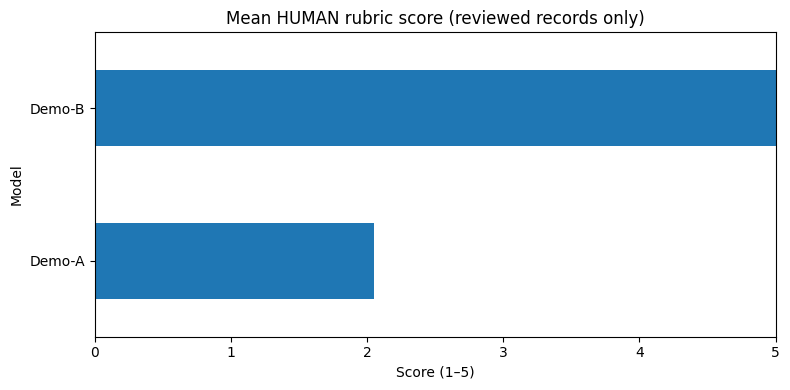

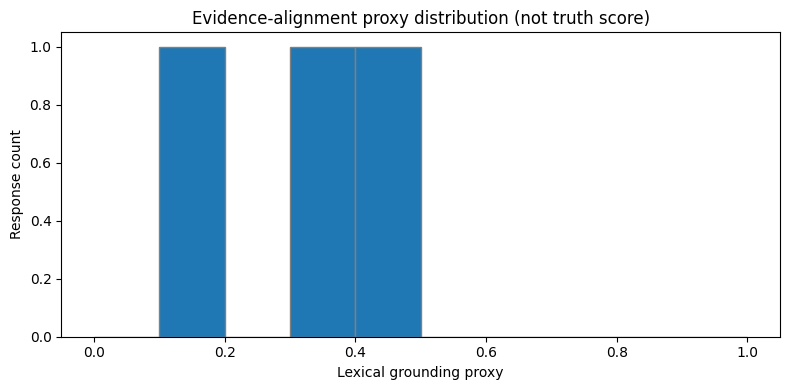

In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

if len(flat_df):
    reviewed = flat_df.dropna(subset=['human_weighted_score']).copy()
    print('Total records:', len(flat_df), '| Human rubric completed:', len(reviewed), '| Pending:', len(flat_df)-len(reviewed))
    print('Human-confirmed hallucination labels:', flat_df['human_hallucination_label'].value_counts().to_dict())
    group = flat_df.groupby('model', dropna=False).agg(
        responses=('id','size'),
        human_reviewed=('human_weighted_score','count'),
        human_score_mean=('human_weighted_score','mean'),
        evidence_alignment_mean=('grounding_score','mean'),
        flag_ratio_mean=('unsupported_sentence_ratio','mean'),
    ).reset_index()
    display(group.round(3))
    if len(reviewed):
        means = reviewed.groupby('model')['human_weighted_score'].mean().sort_values()
        fig, ax = plt.subplots(figsize=(8, 4))
        means.plot(kind='barh', ax=ax)
        ax.set(title='Mean HUMAN rubric score (reviewed records only)', xlabel='Score (1–5)', ylabel='Model', xlim=(0, 5))
        plt.tight_layout(); plt.show()
    evidence_df = flat_df.dropna(subset=['grounding_score'])
    if len(evidence_df):
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.hist(evidence_df['grounding_score'], bins=np.linspace(0,1,11), edgecolor='gray')
        ax.set(title='Evidence-alignment proxy distribution (not truth score)', xlabel='Lexical grounding proxy', ylabel='Response count')
        plt.tight_layout(); plt.show()

## 6. Inspect sentence-level review flags

In [6]:
RECORD_INDEX = 0  # change to any valid index
if results:
    chosen = results[min(RECORD_INDEX, len(results)-1)]
    print('Case:', chosen['id'], '| Model:', chosen['model'])
    print('Prompt:', chosen['prompt'])
    print('Response:', chosen['response'])
    print('Human feedback:', chosen['human_feedback'] or '(not yet supplied)')
    print('Lexical flag status:', chosen['grounding_status'])
    display(pd.DataFrame(chosen['sentence_scores']))
    print('Reminder: flagged sentences require verification against reliable references.')

Case: CASE-001 | Model: Demo-A
Prompt: Can binary search run correctly on an unsorted array?
Response: Yes. Standard binary search always works on unsorted arrays because it halves the range.
Human feedback: False general claim about binary search correctness; verify against algorithm invariant.
Lexical flag status: heuristic_evidence_alignment_only


,sentence,evidence_similarity,needs_review
0,Standard binary search always works on unsorte...,0.1658,True


Reminder: flagged sentences require verification against reliable references.


## 7. Interactive human-review form (Colab widgets)
Choose a case, assign all four scores, select hallucination label only after checking evidence, write feedback, and click **Save review & re-evaluate**. Other cells may need rerunning to refresh charts/exports.

In [7]:
import ipywidgets as widgets
from IPython.display import display, clear_output

if len(df) == 0:
    print('No records to review')
else:
    case_selector = widgets.Dropdown(options=[(f"{i}: {str(row.get('id',''))} | {str(row.get('model',''))}", i) for i, row in df.iterrows()], description='Case:')
    sliders = {name: widgets.IntSlider(value=3,min=1,max=5,step=1,description=name.replace('_',' ').title(),style={'description_width':'130px'},layout=widgets.Layout(width='450px')) for name in DIMENSIONS}
    hall_selector = widgets.Dropdown(options=['not_reviewed','yes','no','uncertain'],description='Hallucination:',style={'description_width':'130px'})
    feedback = widgets.Textarea(description='Feedback:',placeholder='State factual evidence, reasoning errors, and actionable fixes...',layout=widgets.Layout(width='680px',height='110px'),style={'description_width':'130px'})
    case_text=widgets.HTML()
    save_button=widgets.Button(description='Save review & re-evaluate', button_style='success', icon='check')
    output=widgets.Output()
    def change_case(change=None):
        global df
        idx=case_selector.value
        row=df.loc[idx]
        case_text.value=f"<b>Prompt:</b> {str(row.get('prompt',''))[:400]}<hr><b>Response:</b> {str(row.get('response',''))[:600]}<hr><b>Evidence:</b> {str(row.get('evidence',''))[:600]}"
        for name,slider in sliders.items():
            val=row.get(name,'')
            slider.value=int(float(val)) if str(val).strip() and pd.notna(val) else 3
        oldlabel=str(row.get('human_hallucination_label','not_reviewed') or 'not_reviewed').lower()
        hall_selector.value=oldlabel if oldlabel in hall_selector.options else 'not_reviewed'
        feedback.value=str(row.get('human_feedback','') or '')
    def save_review(button):
        global df, results, errors, flat_df
        idx=case_selector.value
        for name,slider in sliders.items(): df.loc[idx,name]=slider.value
        df.loc[idx,'human_hallucination_label']=hall_selector.value
        df.loc[idx,'human_feedback']=feedback.value
        results,errors=run_batch(df)
        flat_df=pd.DataFrame([flat_export(r) for r in results])
        with output:
            clear_output(wait=True)
            current=next((r for r in results if str(r['id'])==str(df.loc[idx].get('id',''))), None)
            print('Saved reviewer inputs. Weighted score:', current['human_weighted_score'] if current else '(not found)')
            print('Rerun visualization and export cells for updated files.')
    case_selector.observe(change_case,names='value')
    save_button.on_click(save_review)
    change_case()
    display(widgets.VBox([case_selector,case_text,*sliders.values(),hall_selector,feedback,save_button,output]))

## 8. Export CSV + JSON + errors, and optional ZIP download

In [8]:
import json, zipfile
from datetime import datetime, timezone

# Always reflect latest saved widget data.
results, errors = run_batch(df)
flat_df = pd.DataFrame([flat_export(r) for r in results])
paths = {'csv':BASE/'evaluation_results.csv','json':BASE/'evaluation_results.json','errors':BASE/'validation_errors.json', 'input':BASE/'reviewed_input.csv'}
flat_df.to_csv(paths['csv'],index=False,encoding='utf-8-sig')
paths['json'].write_text(json.dumps({
    'metadata':{'generated_at_utc':datetime.now(timezone.utc).isoformat(), 'threshold':EVIDENCE_SIMILARITY_THRESHOLD,
                'warning':'Lexical evidence alignment and flags are NOT verified factual accuracy or hallucination measurements.'},
    'results':results}, indent=2,ensure_ascii=False,default=str),encoding='utf-8')
paths['errors'].write_text(json.dumps(errors,indent=2,ensure_ascii=False),encoding='utf-8')
df.to_csv(paths['input'], index=False, encoding='utf-8-sig')
zip_path=BASE/'llm_evaluation_outputs.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in paths.values():z.write(p,p.name)
print('Files generated:')
for p in [*paths.values(),zip_path]:print(' -',p)

DOWNLOAD_ZIP = False  # set True in Google Colab to download files to your computer
if DOWNLOAD_ZIP:
    try:
        from google.colab import files
        files.download(str(zip_path))
    except ImportError:
        print('Open the ZIP path above (download is supported directly in Colab).')

Files generated:
 - /content/llm_eval/evaluation_results.csv
 - /content/llm_eval/evaluation_results.json
 - /content/llm_eval/validation_errors.json
 - /content/llm_eval/reviewed_input.csv
 - /content/llm_eval/llm_evaluation_outputs.zip


## 9. Quality-assurance smoke tests

In [9]:
# Basic evaluator behavior and non-fabrication checks
assert weighted_human_score({'factual_accuracy':5,'reasoning':5,'relevance':5,'completeness':5})==5.0
assert weighted_human_score({'factual_accuracy':5,'reasoning':None,'relevance':5,'completeness':5}) is None
assert grounding_signals('This claim needs review.', '')['grounding_score'] is None
assert len(results)+len(errors)==len(df)
assert paths['csv'].exists() and paths['json'].exists() and zip_path.exists()
try:
    evaluate_record({'prompt':'test','response':''})
    raise AssertionError('Expected validation error')
except ValueError: pass
print('PASS: scoring, missing scores, missing evidence, batch accounting, exports, validation')

PASS: scoring, missing scores, missing evidence, batch accounting, exports, validation


## 10. How to present this project in a Turing interview

> “I built a reproducible LLM evaluation framework with a human scoring rubric for factual accuracy, reasoning, relevance and completeness, plus lexical evidence-grounding diagnostics and sentence-level flags. The tool supports batch evaluation, annotator feedback, model comparison, CSV/JSON reporting and an interactive human-review workflow. I explicitly distinguish model-assisted heuristics from verified ground truth and document limitations and test coverage.”

**Next iteration:** multi-annotator agreement, reference-linked claim verification, more challenging benchmark cases, and a separately validated LLM-as-a-Judge baseline.

**Data note:** Do not upload confidential documents into an external runtime without authorization. The notebook's sample dataset is illustrative, not an audited benchmark.